# Creating Sounding Plots

This tutorial creates SounderPy Sounding plots! 

#### Here we will explore:   
- Full Soundings
- Plots in Dark Mode
- Color blind friendly settings
- Saving soundings to a file

In [1]:
# First lets import SounderPy. Its fun to import as 'spy'!
import sounderpy as spy

## Load some data to plot

Here we can load some data with SounderPy.

Let's investigate OUN (Norman, OK) observations for El-Reno 2013. We can use the ``get_obs_data()`` function to do this

In [2]:
clean_data = spy.get_obs_data('oun', '2013', '05', '31', '18')

> OBSERVED DATA ACCESS FUNCTION
  -----------------------------------


    > PROFILE FOUND: OUN on 05/31/2013 at 18z | From UW (ID: 72357)
    > COMPLETE --------
    > RUNTIME: 00:00:07
    > SUMMARY: 18Z Launch for KOUN, Norman at 05-31-2013-18Z


 
    > THERMODYNAMICS --------------------------------------------- 
    --- SBCAPE: 5233.5 | MUCAPE: 5233.5 | MLCAPE: 3615.9 | MUECAPE: 3746.8
    --- MU 0-3: 133.1 | MU 0-6: 1136.4 | SB 0-3: 133.1 | SB 0-6: 1136.4
 
    > KINEMATICS ------------------------------------------------- 
    --- 0-500 SRW: 24.8 knot | 0-500 SWV: 0.011 | 0-500 SHEAR: 8.9 | 0-500 SRH: 59.8
    --- 1-3km SRW: 17.1 knot | 1-3km SWV: 0.004 | 1-3km SHEAR: 16.3 | | 1-3km SRH: 68.2
 


## Build a full sounding plot

Here we use the most basic version of the ``build_sounding()`` function to build a 'full sounding'. Making a SounderPy sounding figure is as simple as:

> SOUNDING PLOTTER FUNCTION
  ---------------------------------
    > PREPARING DATA


    > BUILDING SKEW-T LOG-P DIAGRAM


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KTLX Scan: 2013-05-31 | 18:01z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS
    > PLOTTING SOUNDING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:24


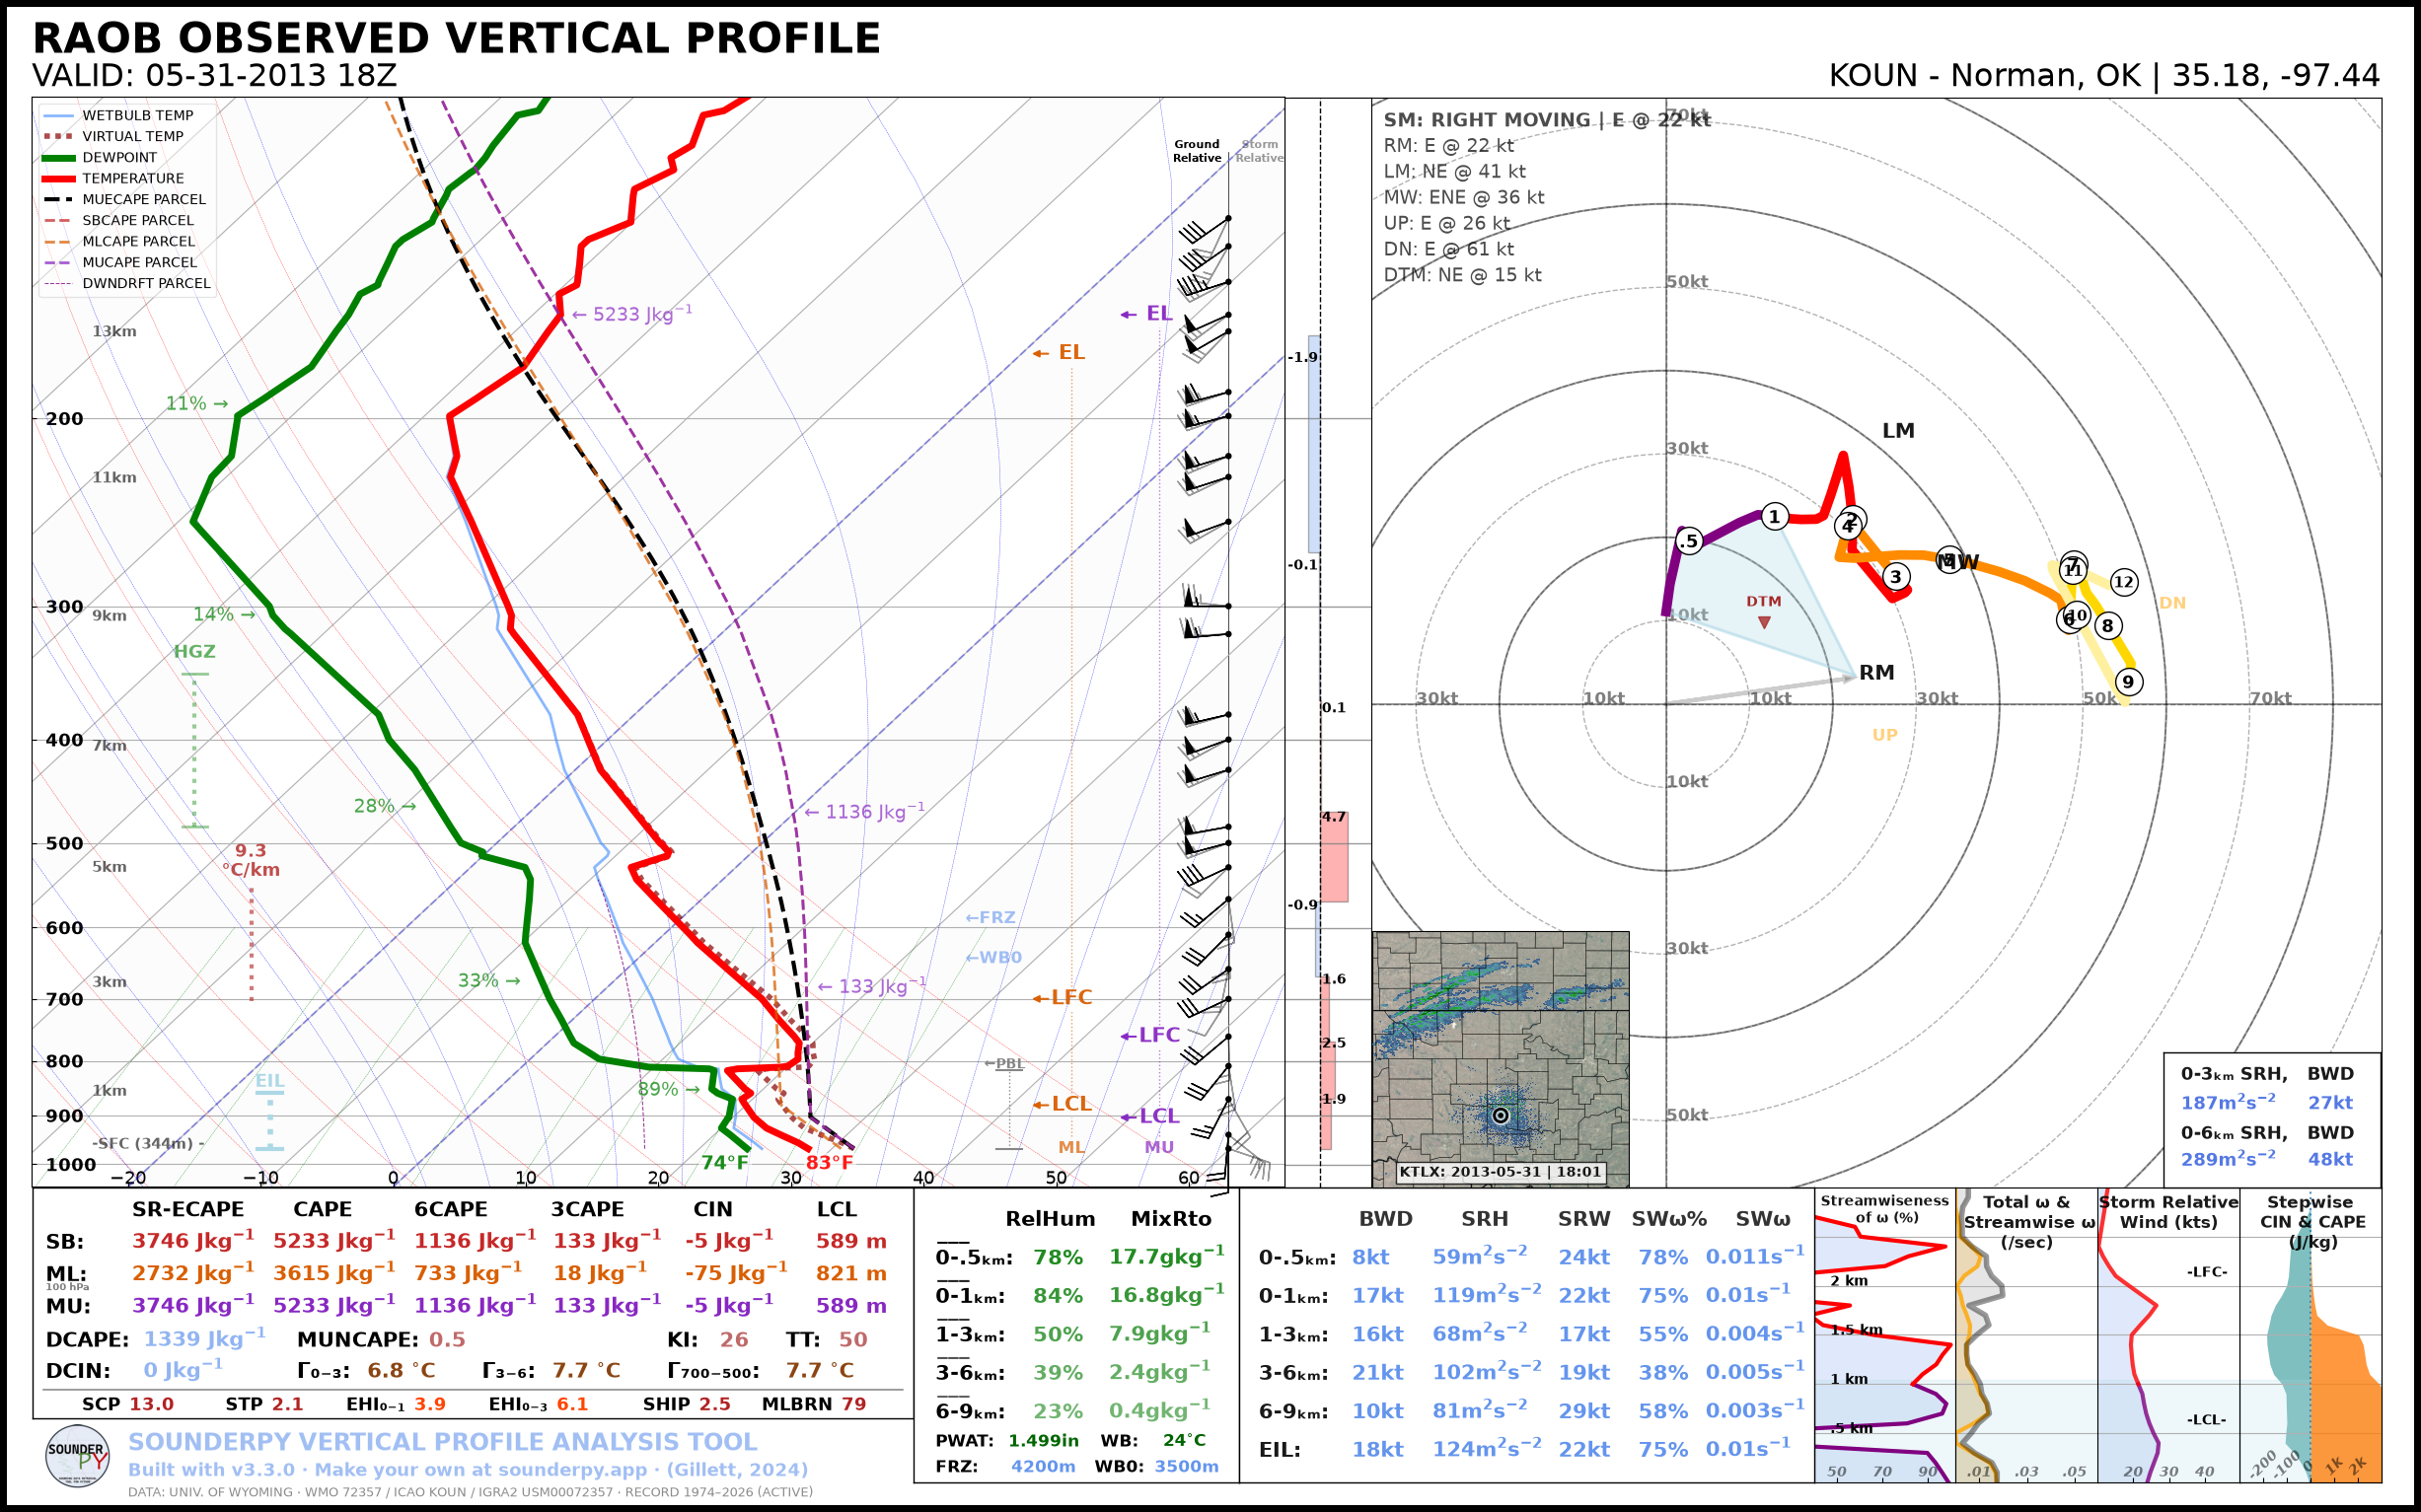

In [3]:
# lets make a full sounding!
# radar='single' shows the nearest NEXRAD site's reflectivity on the map.
# The default radar mosaic only keeps about the last month, so it can't cover this date.
spy.build_sounding(clean_data, radar='single')

## Playing with sounding settings

Now we can adjust a few settings to customize the plot a little bit.

To do so, let's first study the `build_sounding()` function...

#### `build_sounding(clean_data, color_blind=False, dark_mode=False, storm_motion='right_moving', special_parcels=None, radar='mosaic', radar_time='sounding', map_zoom=2, modify_sfc=None, show_theta=False, hodo_boundary=None, dpi=100, save=False, filename='sounderpy_sounding', max_levels=250, ylim=None, theme=None, sr_hodo=False, mode='severe', show_obs=False)`

where:

- `clean_data` (dict, required) – the dictionary of data to be plotted

- `color_blind` (bool, optional, default is False) – change the dewpoint trace from green to blue for improved readability for color deficient users/readers.

- `dark_mode` (bool, optional, default is False) – True will invert the color scheme for a 'dark-mode' sounding.

- `storm_motion` (str or list of floats, optional, default is 'right_moving') – the storm motion used for plotting and calculations. Custom storm motions are accepted as a list of floats representing direction and speed. Ex: [270.0, 25.0] where '270.0' is the direction in degrees and '25.0' is the speed in kts. See the documentation for more details.

- `special_parcels` (nested list of two lists, optional) – a nested list of special parcels from the ecape_parcels library. The nested list should be a list of two lists ([[a, b], [c, d]]) where the first list should include 'highlight parcels' and second list should include 'background parcels'. Another option is 'simple', which removes all advanced parcels making the plot quicker. See the documentation for more details.

- `radar` (str or None, optional, default is 'mosaic') – the radar shown on the map inset: 'mosaic' (national reflectivity mosaic), 'single' (the nearest NEXRAD site), or None (no radar). **Note: radar mosaic data only goes back about 1 month from the current date, so use 'single' for older cases.**

- `radar_time` (str or datetime, optional, default is 'sounding') – radar valid time. May be 'sounding' (the valid time of the sounding data), 'now' (current time/date), or a `datetime`.

- `map_zoom` (int, optional, default is 2) – a 'zoom' level for the map inset. **Note: setting `map_zoom=0` will hide the map**

- `modify_sfc` (None or dict, optional, default is None) – a `dict` in the format `{'T': 25, 'Td': 21, 'ws': 20, 'wd': 270}` to modify the surface values of the `clean_data` dict. See the documentation for more details.

- `show_theta` (bool, optional, default is False) – replace the piecewise CAPE plot with theta & theta-e.

- `hodo_boundary` (dict, optional) – draw one or more 'boundary' lines on the hodograph, given as angles and colors.

- `dpi` (int, optional, default is 100) – resolution of the figure.

- `save` (bool, optional, default is False) – whether to show the plot inline or save to a file.

- `filename` (str, optional, default is 'sounderpy_sounding') – the filename to save to if `save=True`.

- `max_levels` (int or None, optional, default is 250) – the most vertical levels used; longer profiles are thinned. None uses every level.

- `ylim` (tuple, optional) – the skew-T's pressure range as (bottom, top) in hPa, such as (1000, 700), to zoom in on part of the atmosphere.

- `theme` (dict, optional) – changes to the figure's colors, such as `{'border': 'k', 'temperature': 'navy'}`.

- `sr_hodo` (bool, optional, default is False) – draw the hodograph storm relative.

- `mode` (str, optional, default is 'severe') – 'severe' for the standard sounding, 'winter' for the winter sounding, or 'auto' to pick winter when the surface wet-bulb temperature is below 35 °F.

- `show_obs` (bool, optional, default is False) – winter sounding only: show the nearest surface observation (METAR).

See every option in detail: *https://kylejgillett.github.io/sounderpy/reference/plottingdata.html#building-soundings*

This case is from 2013, older than the radar mosaic archive, so the examples below use `radar='single'` to show reflectivity from the nearest NEXRAD site.



Lets try the color_blind setting:

> SOUNDING PLOTTER FUNCTION
  ---------------------------------
    > PREPARING DATA


    > BUILDING SKEW-T LOG-P DIAGRAM


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KTLX Scan: 2013-05-31 | 18:01z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS
    > PLOTTING SOUNDING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:22


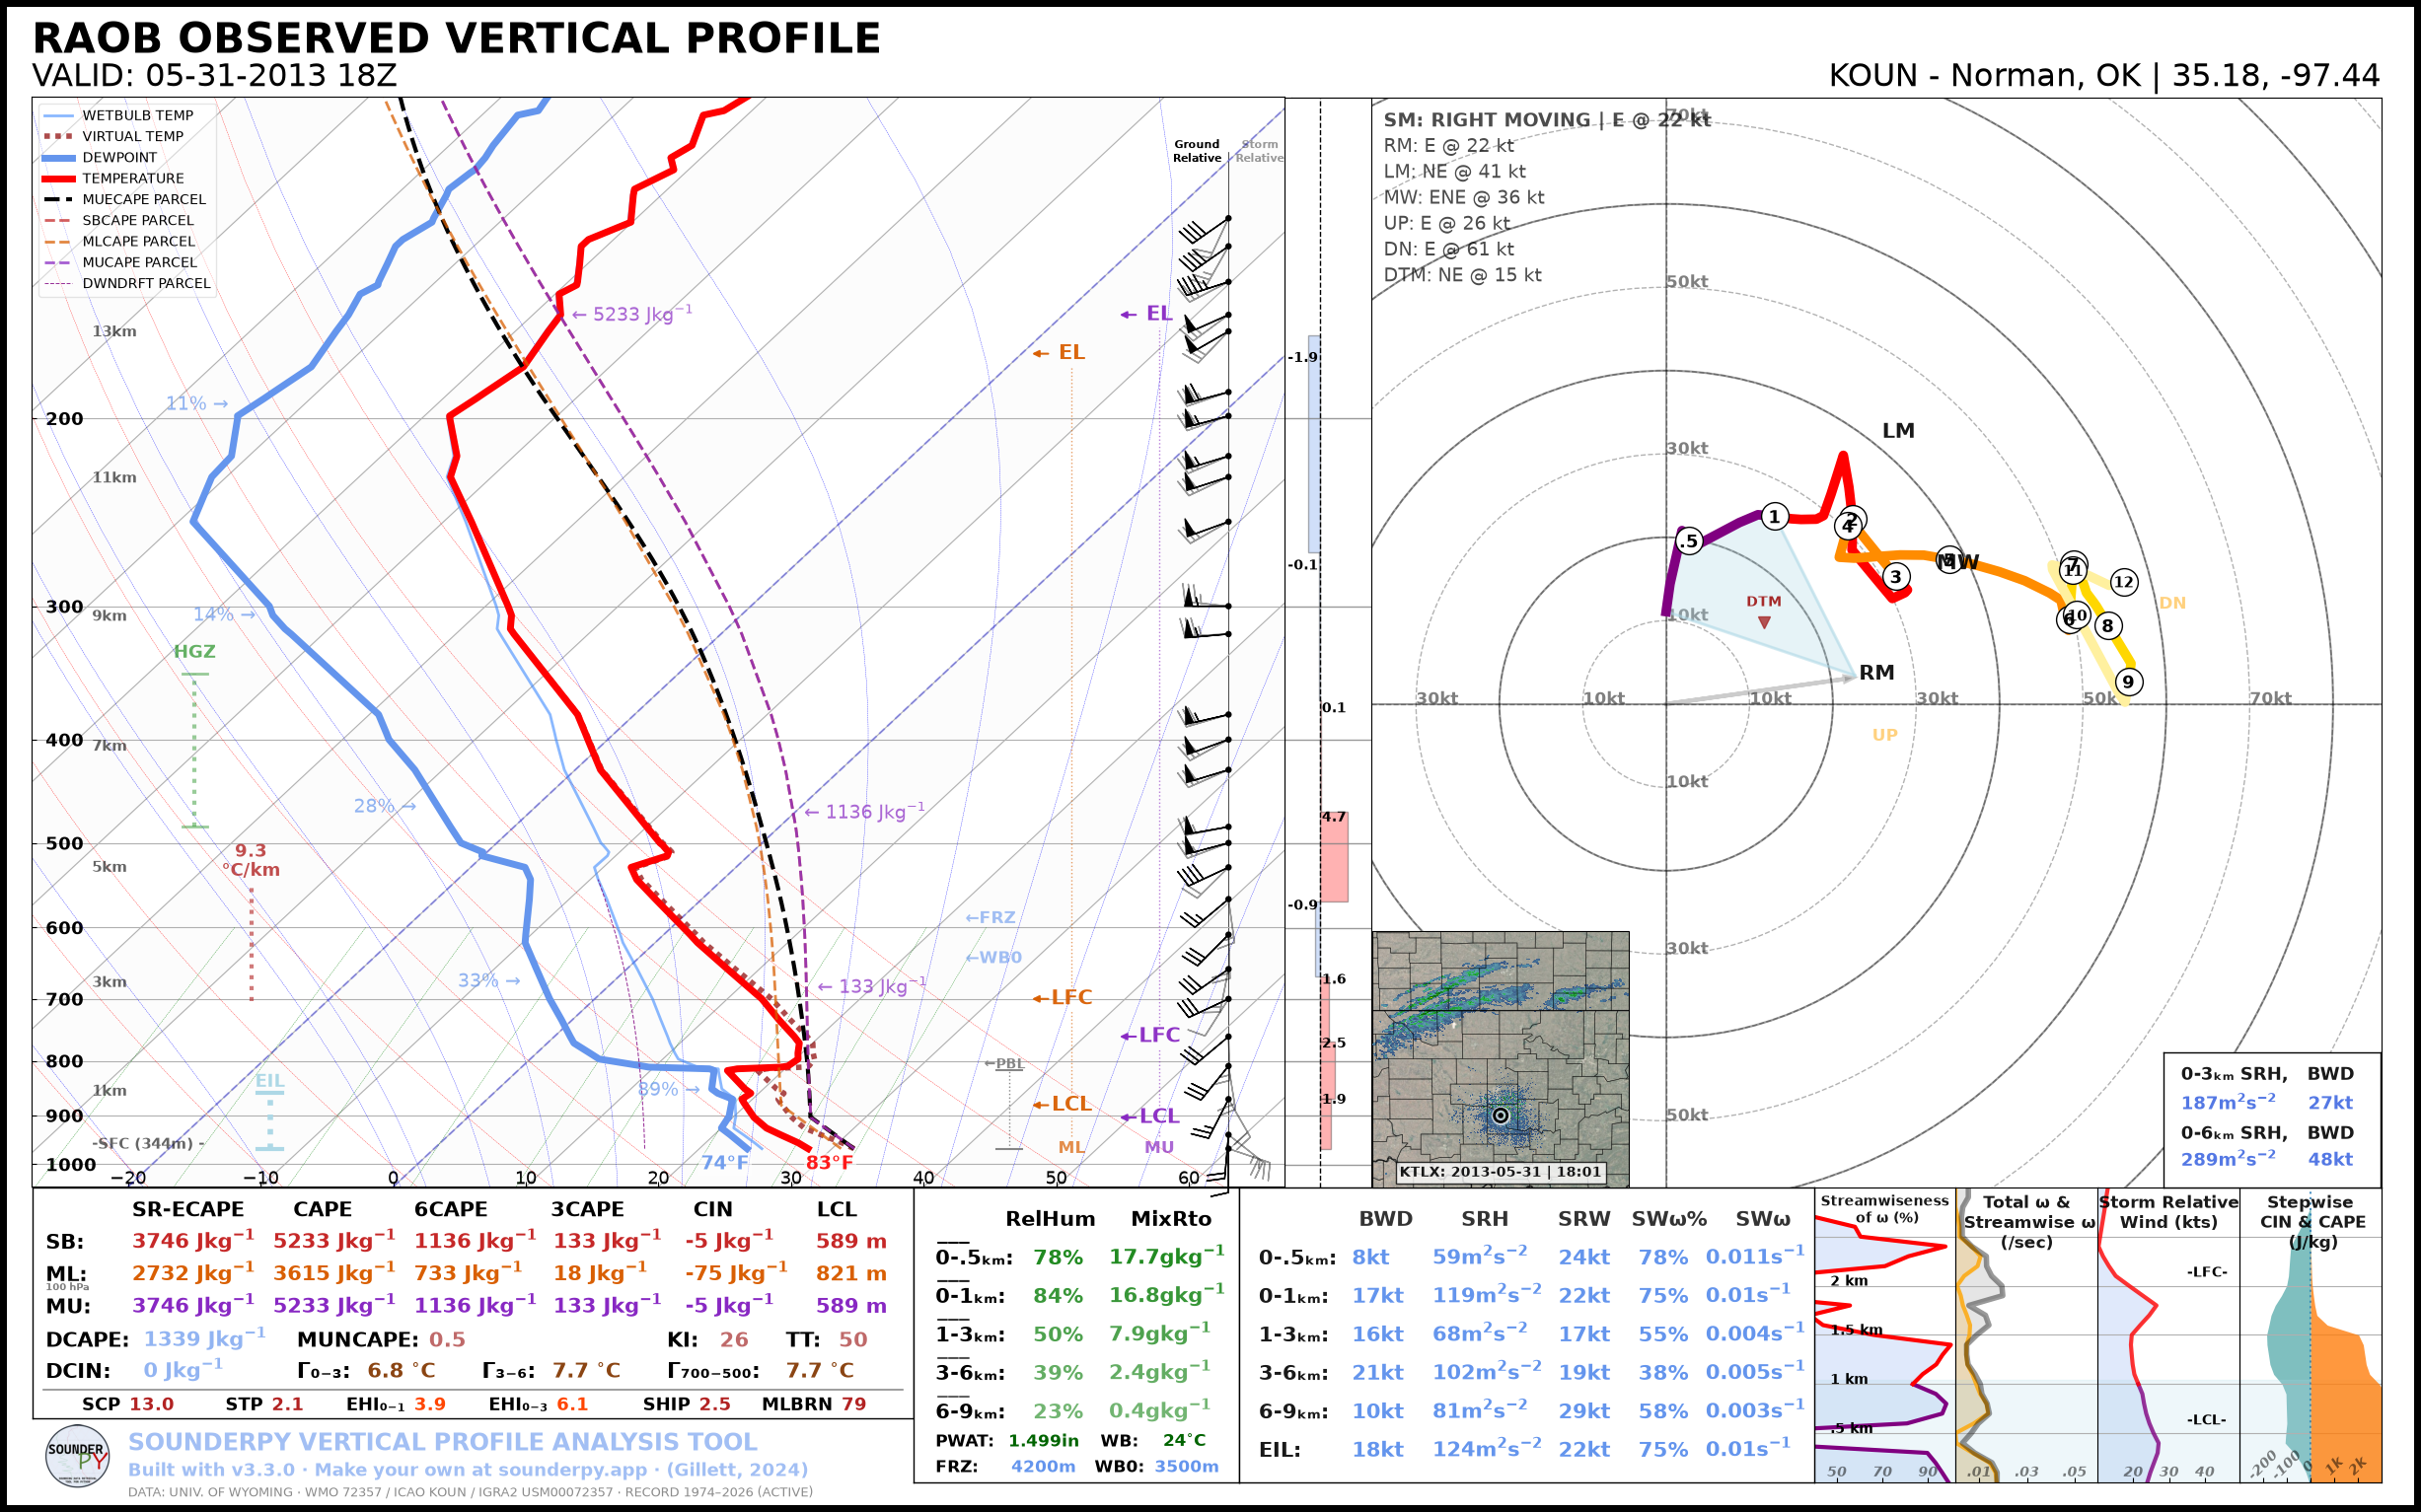

In [4]:
# color_blind turned on!
spy.build_sounding(clean_data, color_blind=True, radar='single')

And now, for probably the coolest part: dark mode!

> SOUNDING PLOTTER FUNCTION
  ---------------------------------
    > PREPARING DATA


    > BUILDING SKEW-T LOG-P DIAGRAM


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KTLX Scan: 2013-05-31 | 18:01z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


    > PLOTTING SOUNDING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:19


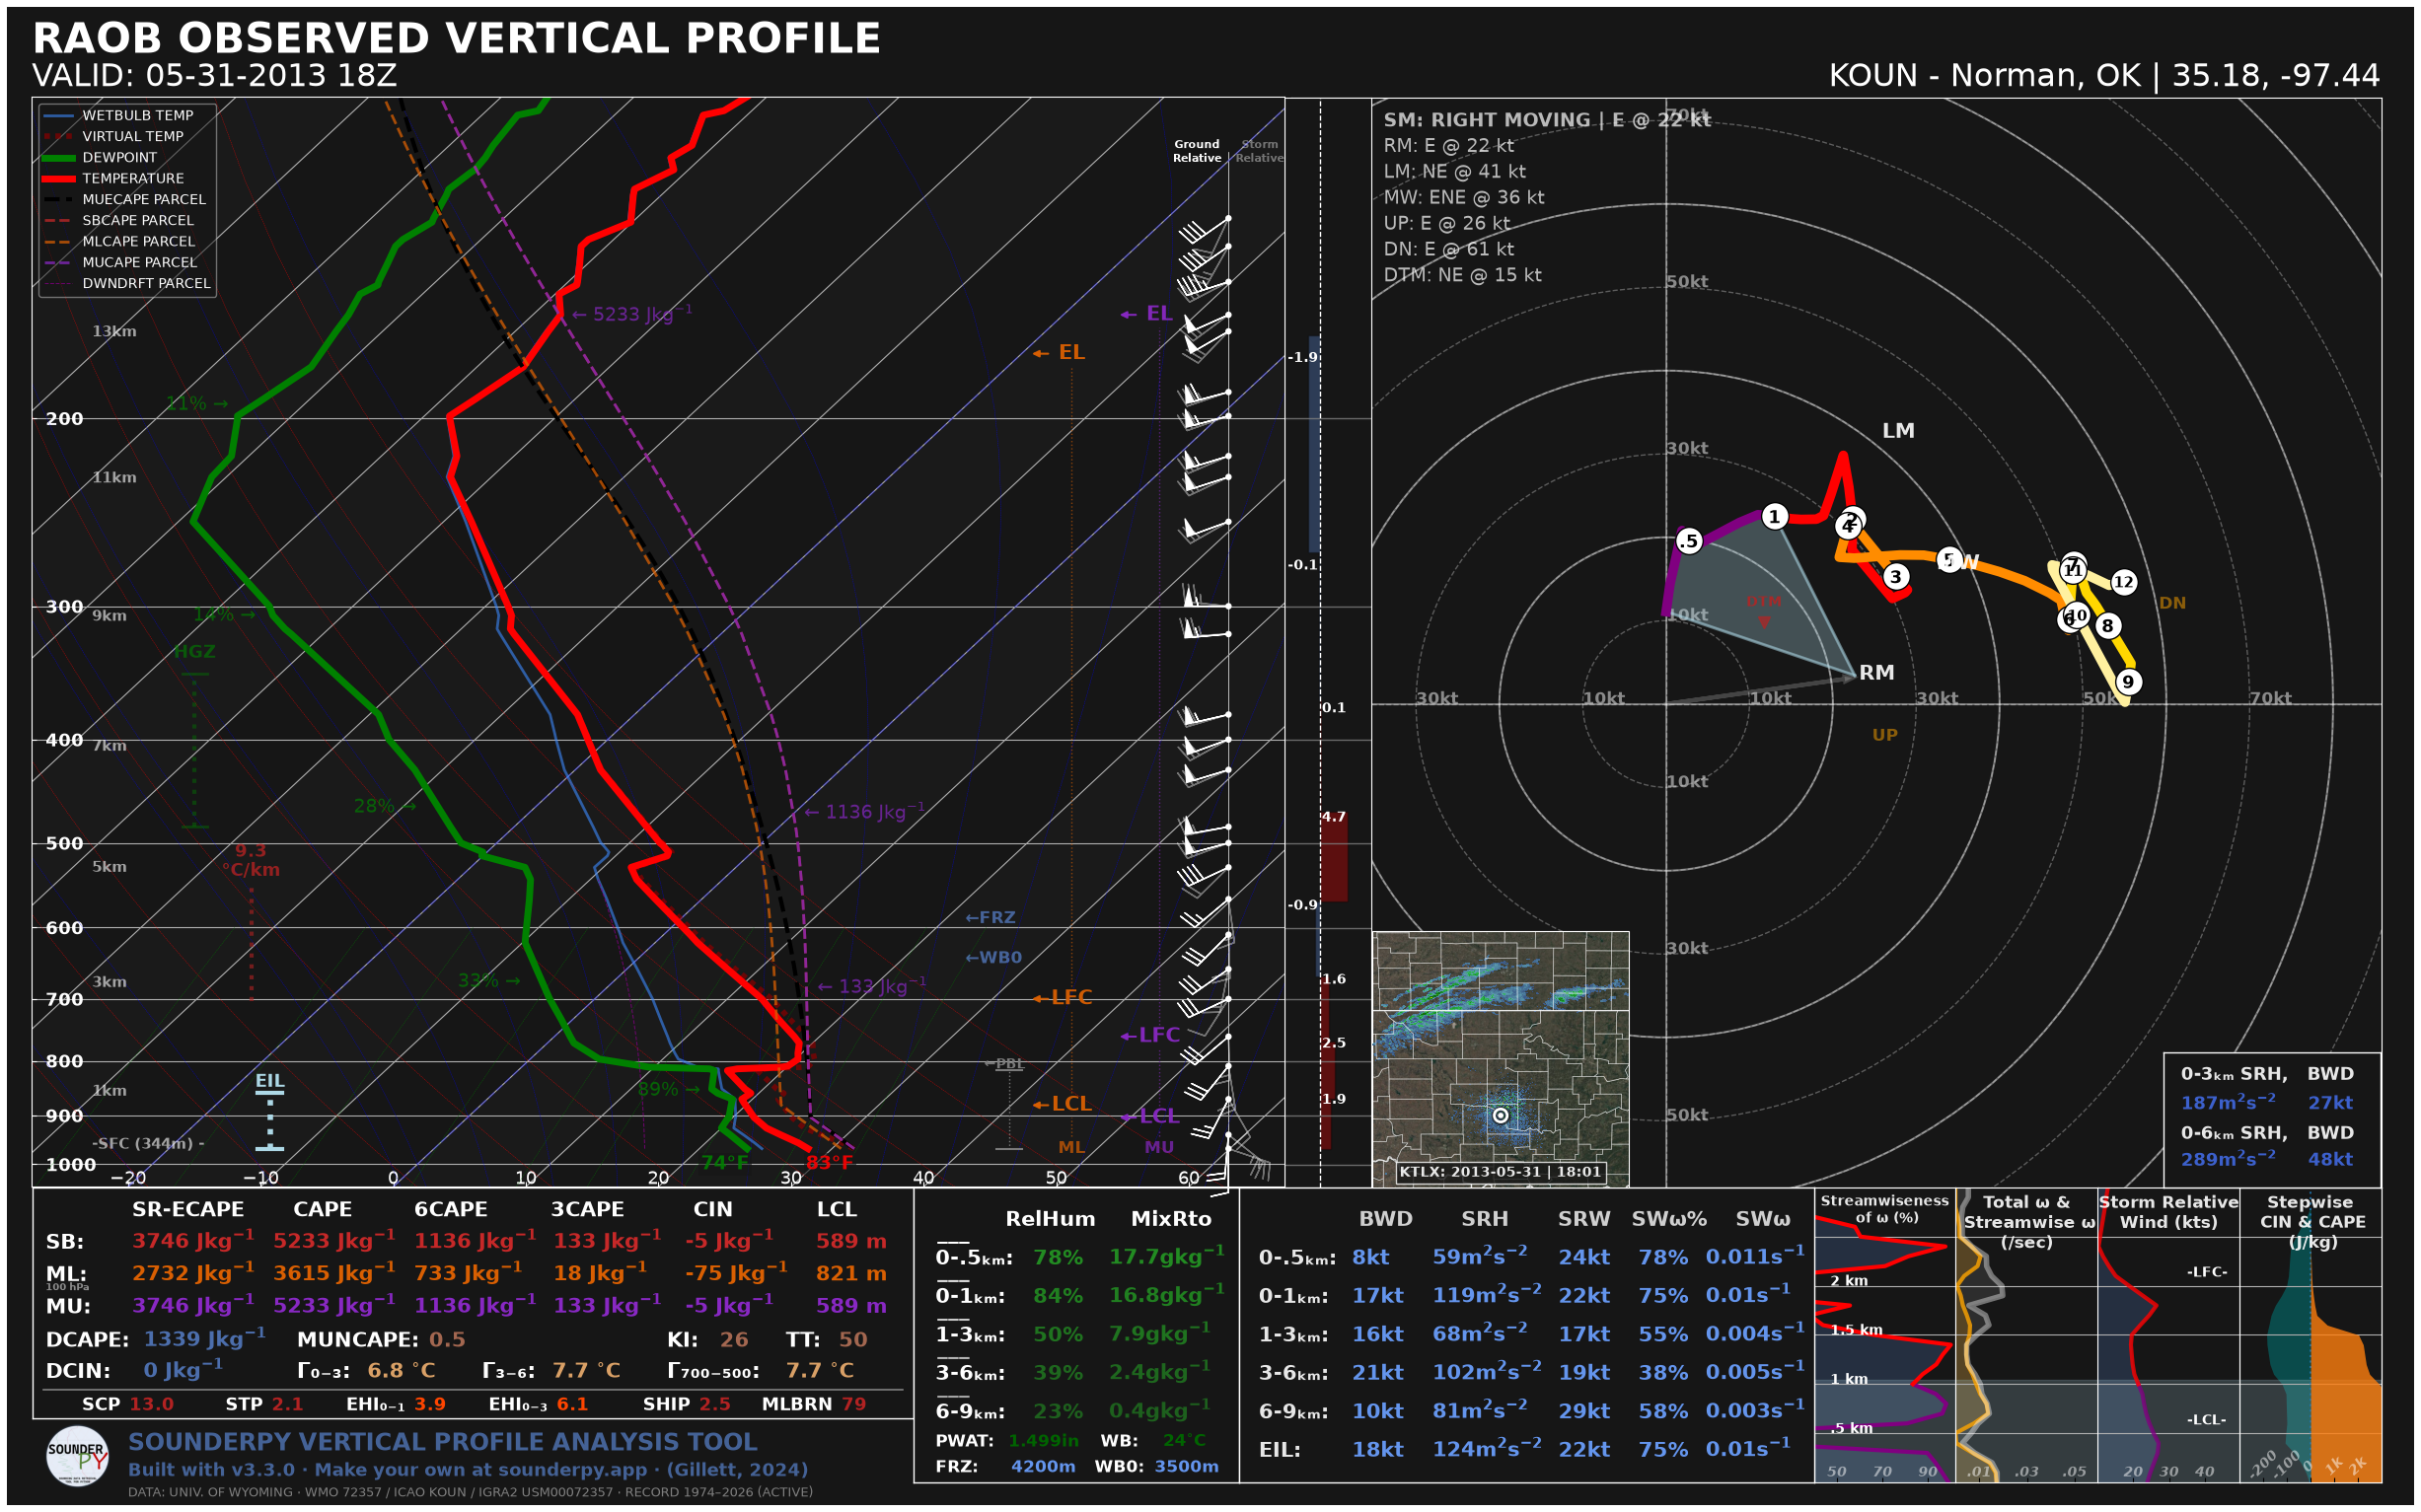

In [5]:
# dark_mode turned on!
spy.build_sounding(clean_data, dark_mode=True, radar='single')

> SOUNDING PLOTTER FUNCTION
  ---------------------------------
    > PREPARING DATA


    > BUILDING SKEW-T LOG-P DIAGRAM


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KTLX Scan: 2013-05-31 | 18:01z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


    > PLOTTING SOUNDING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:14


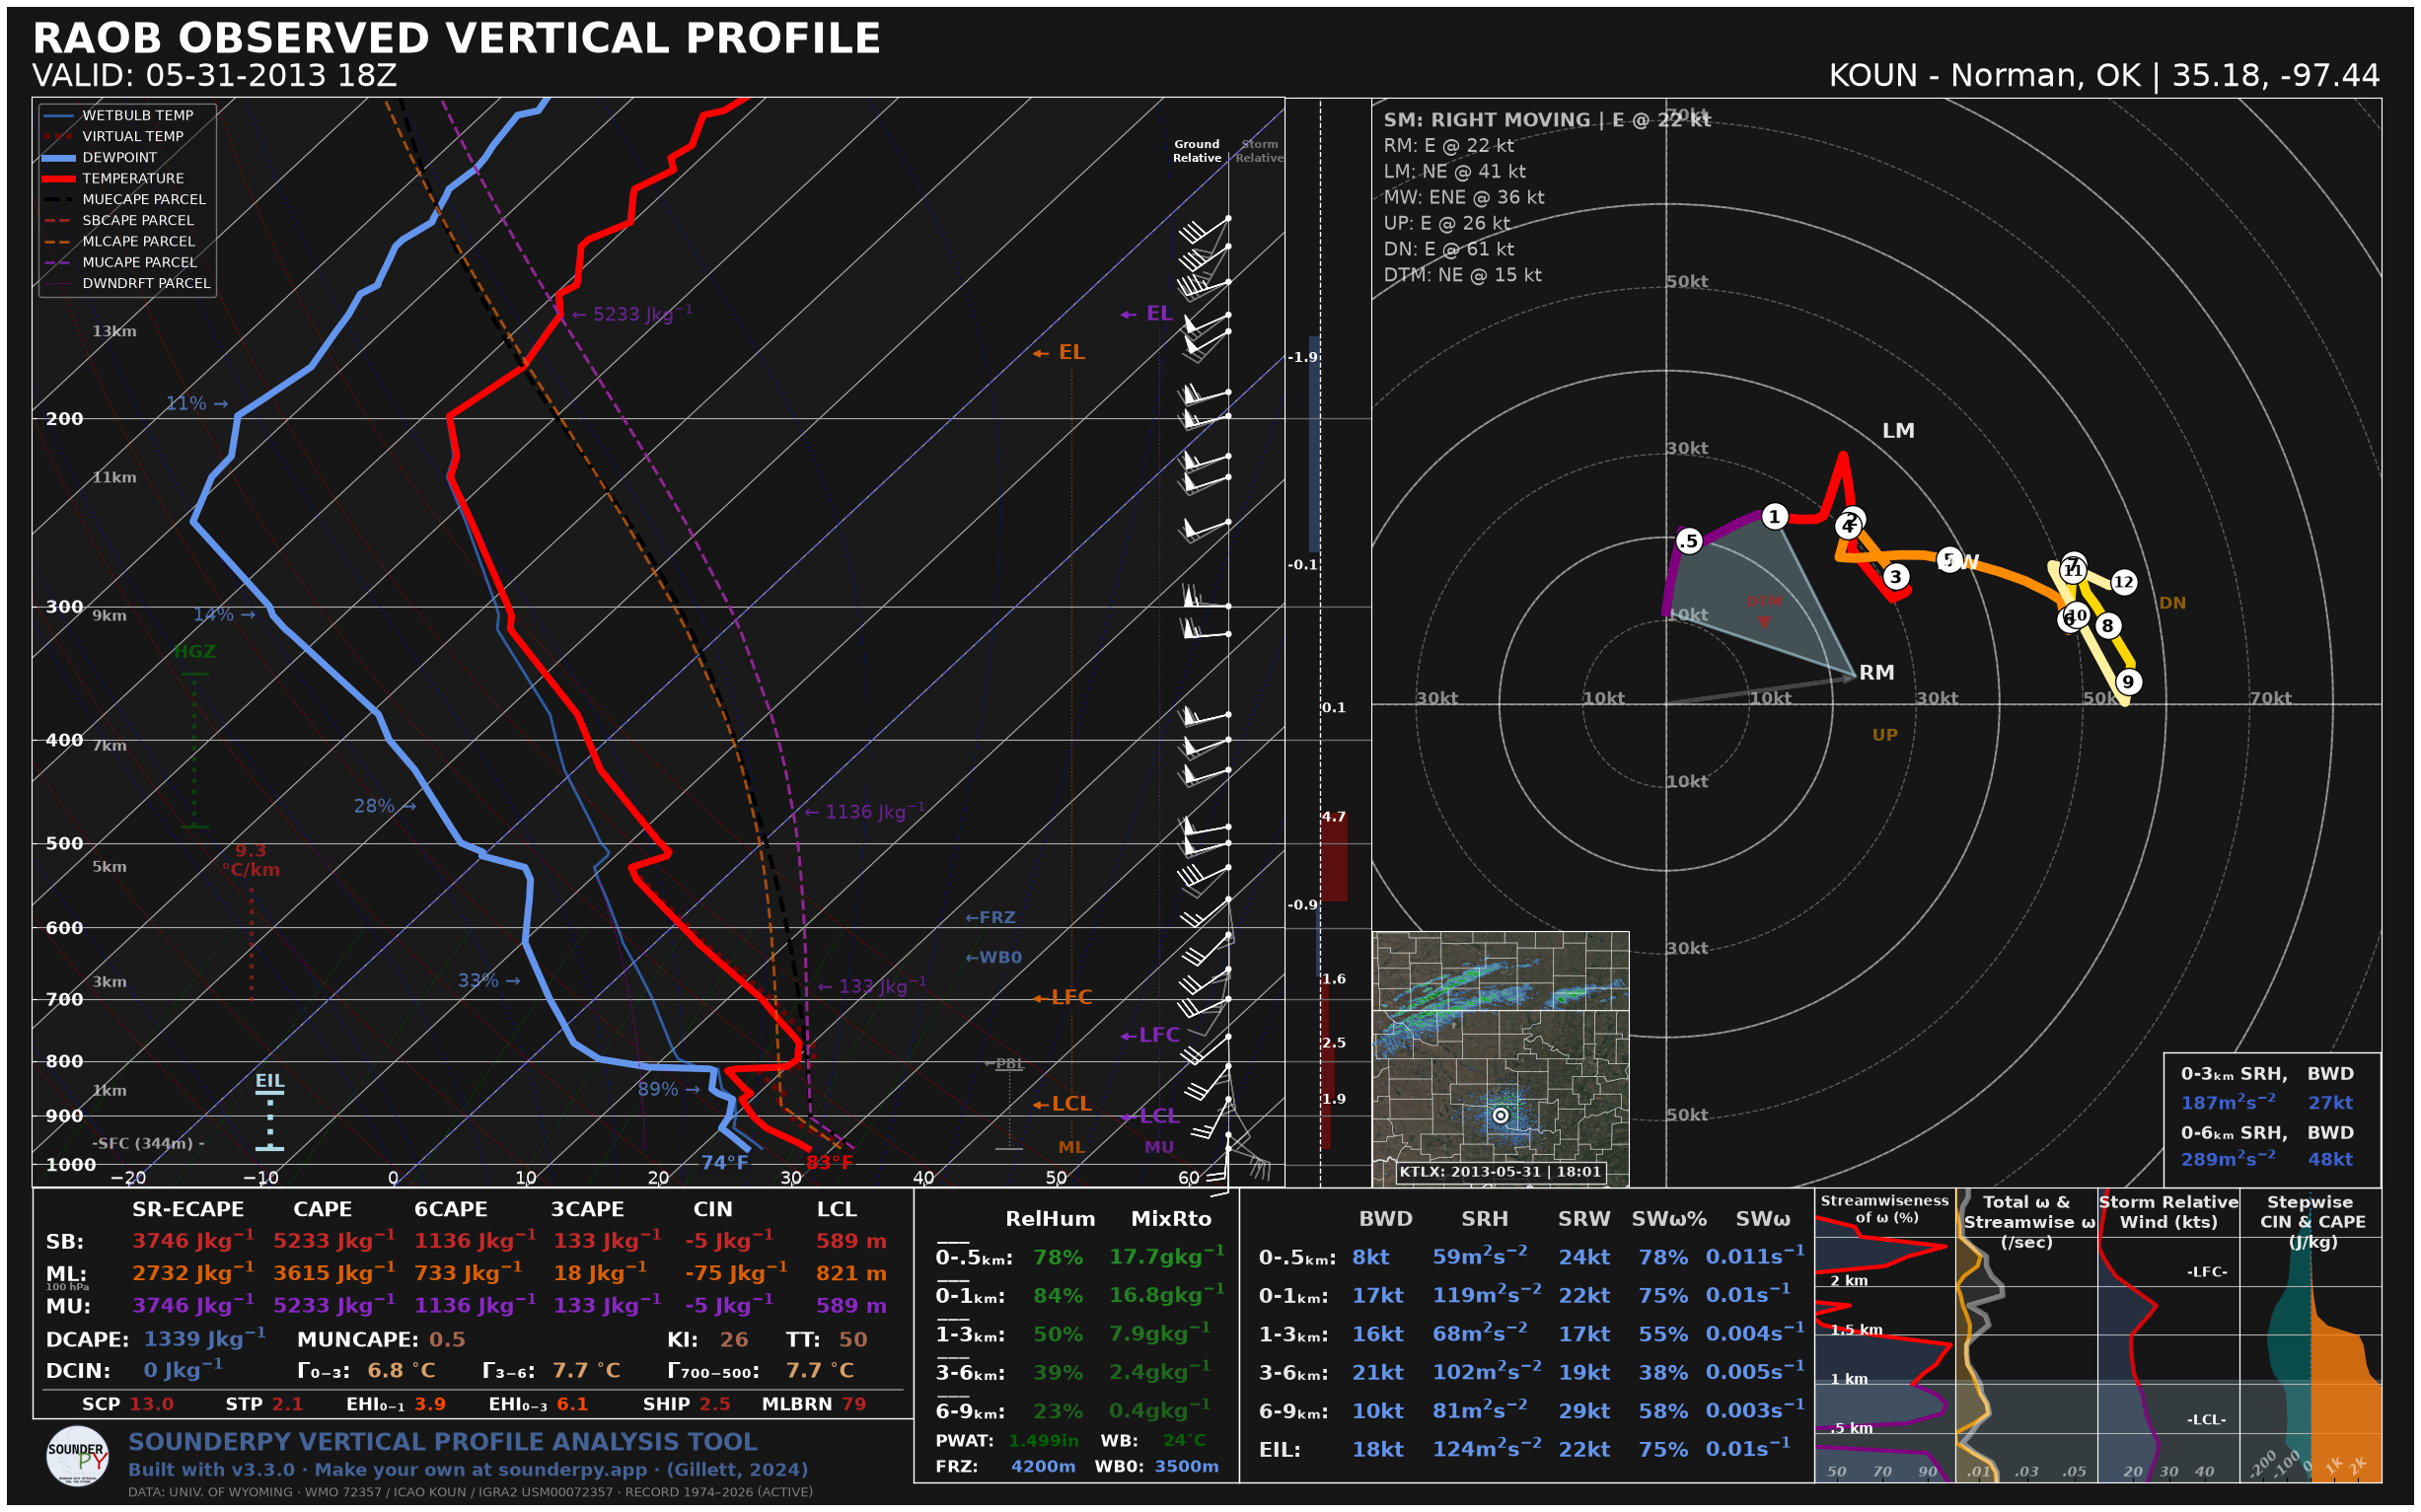

In [6]:
# dark_mode and color_blind turned on!
spy.build_sounding(clean_data, dark_mode=True, color_blind=True, radar='single')

## Saving plots as a file

By default, SounderPy is set to show plots inline. If you want/need to save them to a file, SounderPy offers that option! 

Just set the `save` kwarg to True, and give it a file name using the `filename` kwarg! 

### IMPORTANT NOTE!!!

- If your plots come out with a funky layout when displaying them inline, it may be due to your screen resolution. 
- In the event that this is the case, simply use the `save=True` option to save plots to a file!

In [7]:
#spy.build_sounding(clean_data, save=True, filename='sounderpy_2013051318z_OUN')